In [1]:
# import necessary modules
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sn
import os
from wordcloud import WordCloud

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "dataset.csv"

feedback = pd.read_csv(DATA_PATH)

feedback.head(5)

,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


In [2]:
#get the number of rows and cols
print(f"No.of rows: {feedback.shape[0]}, No. of Colums: {feedback.shape[1]}\n")
feedback.info()

No.of rows: 205052, No. of Colums: 6

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205052 entries, 0 to 205051
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   product_name   205052 non-null  object
 1   product_price  205052 non-null  object
 2   Rate           205052 non-null  object
 3   Review         180388 non-null  object
 4   Summary        205041 non-null  object
 5   Sentiment      205052 non-null  object
dtypes: object(6)
memory usage: 9.4+ MB


In [3]:
#convert product_price and Rate to numeric columns
rows_before = len(feedback)
print(f"before deleting invalid rating : {rows_before}")
cols_to_covert = ['Rate', 'product_price']
feedback[cols_to_covert] = feedback[cols_to_covert].apply(pd.to_numeric, errors='coerce')
#delete rows with inavlid Rate
feedback = feedback.dropna(subset=['Rate'])
#convert rate column in to int
feedback['Rate'] = feedback['Rate'].astype(int)
print(f"rows after Rate cleaned : {len(feedback)}")
feedback.info()

before deleting invalid rating : 205052
rows after Rate cleaned : 205049
<class 'pandas.core.frame.DataFrame'>
Index: 205049 entries, 0 to 205051
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   product_name   205049 non-null  object 
 1   product_price  205049 non-null  float64
 2   Rate           205049 non-null  int64  
 3   Review         180385 non-null  object 
 4   Summary        205038 non-null  object 
 5   Sentiment      205049 non-null  object 
dtypes: float64(1), int64(1), object(4)
memory usage: 11.0+ MB


In [4]:
# verify that all ratings are between 1 and 5
invalid_rating_range = feedback.loc[
    ~feedback["Rate"].between(1, 5),
    "Rate"
]

print("Out-of-range ratings:", len(invalid_rating_range))

Out-of-range ratings: 0


In [148]:
#get the category in the rating
feedback['Rate'].value_counts().sort_index()
# to do:
# remove the text cells in the 

Rate
1     21300
2      6491
3     16599
4     41894
5    118765
Name: count, dtype: int64

In [149]:
#check the number of empty cells
feedback.isnull().sum()

product_name         0
product_price        0
Rate                 0
Review           24664
Summary             11
Sentiment            0
dtype: int64

In [150]:
#categories in sentiment
feedback['Sentiment'].value_counts()

Sentiment
positive    166579
negative     28231
neutral      10239
Name: count, dtype: int64

In [151]:
#find a crosstab between sentiment and Rate
pd.crosstab(feedback['Rate'], feedback['Sentiment'])

Sentiment,negative,neutral,positive
Rate,,,
1,18793,1233,1274
2,4707,1050,734
3,3023,3660,9916
4,882,1982,39030
5,826,2314,115625


In [152]:
#search noisy chars in Summary column
len(feedback[feedback['Summary'].str.contains(r"[^a-zA-Z0-9\s]", regex=True, na=False)])

12

In [153]:
#search noisy chars in Review column
len(feedback[feedback['Review'].str.contains(r"[^a-zA-Z0-9\s]", regex=True, na=False)])

49036

In [154]:
# derive new rating_sentiment column from mapping product rating
RATE_TO_SENTIMENT = {
    1: "negative",
    2: "negative",
    3: "neutral",
    4: "positive",
    5: "positive",
}

# target label
LABEL_MAPPING = {
    "negative" : 0,
    "neutral" : 1,
    "positive" : 2,
}

feedback["rating_sentiment"] = feedback["Rate"].map(
    RATE_TO_SENTIMENT
)

# clean the provided Sentiment column
feedback["original_sentiment"] = (
    feedback["Sentiment"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Compare original sentiment with the rating-derived sentiment
feedback["labels_agree"] = (
    feedback["rating_sentiment"]
    == feedback["original_sentiment"]
)

print(
    feedback["labels_agree"]
    .value_counts()
)

print(
    feedback["labels_agree"]
    .value_counts(normalize=True)
)

labels_agree
True     181815
False     23234
Name: count, dtype: int64
labels_agree
True     0.88669
False    0.11331
Name: proportion, dtype: float64


In [155]:
# clean the review and summary text string
def clean_text(text: str) -> str:
    """
    Clean the feedback text before vectorization
    # convert all feedback text to lowercase
    # replace the noisy characters with space
    #replace with white space except chars,',', '!', '?'
    #replace whitespace sequence with single space
    """

    # convert all feedback text to lowercase
    text = str(text).lower()

    # replace the noisy characters with space
    text = re.sub(r"[#@*$]+", " ", text)

    #replace with white space except chars,',', '!', '?'
    text = re.sub(r"[^a-zA-Z0-9\s.,!?'-]", " ", text)

    #replace whitespace sequence with single space
    text = re.sub(r"\s+", " ", text)

    #return the cleaned string
    return text.strip()

In [156]:
# create feedback column which combines both Review and summary and clean the noisy chars
feedback['customer_review'] = (feedback['Review'].fillna("").str.strip() + " " + feedback["Summary"].fillna("").str.strip()).str.strip()
feedback = feedback[feedback["customer_review"].ne("")].copy()
feedback["customer_review"] = (feedback["customer_review"].apply(clean_text))
feedback["target_sentiment"] = (feedback["rating_sentiment"])
feedback["target_label"] = feedback["target_sentiment"].map(LABEL_MAPPING)

In [157]:
# check whether identical review text has conflicting target abels
conflicting_reviews = (
    feedback.groupby("customer_review")["target_sentiment"]
    .nunique()
    .gt(1)
    .sum()
)

print("Reviews with conflicting sentiment labels:", conflicting_reviews)

Reviews with conflicting sentiment labels: 442


In [158]:
# sort rows where Rate and Sentiment labels are agreeing 
high_confidence_feedback = feedback[feedback["labels_agree"]].copy()

# sort rows where Rate and Sentiment labels are not agreeing each other
low_confidence_feedback = feedback[~feedback["labels_agree"]].copy()

In [159]:
# no of dataset in the high confidence data
high_confidence_feedback.shape

(181814, 12)

In [160]:
#check the number of duplicate rows 
duplicated = high_confidence_feedback.duplicated().sum()
print(duplicated)
perc_of_duplicated = (duplicated/(high_confidence_feedback.shape[0])) * 100
print(f"No. of duplicated rows : {duplicated}")
print(f"Percent of duplicated: {perc_of_duplicated:.2f}%")

#check the duplicate entries
duplicates = high_confidence_feedback[high_confidence_feedback.duplicated()]
print(duplicates[:5])

32027
No. of duplicated rows : 32027
Percent of duplicated: 17.62%
                                          product_name  product_price  Rate  \
150  MAHARAJA WHITELINE 65 L Desert Air Cooler?????...         7999.0     4   
154  MAHARAJA WHITELINE 65 L Desert Air Cooler?????...         7999.0     5   
248  MAHARAJA WHITELINE 65 L Desert Air Cooler?????...         7999.0     5   
288  MAHARAJA WHITELINE 65 L Desert Air Cooler?????...         7999.0     4   
314  MAHARAJA WHITELINE 65 L Desert Air Cooler?????...         7999.0     5   

                    Review          Summary Sentiment rating_sentiment  \
150            really nice     good product  positive         positive   
154     highly recommended          awesome  positive         positive   
248  mind-blowing purchase  awesome product  positive         positive   
288              wonderful             good  positive         positive   
314       perfect product!     good product  positive         positive   

    original_

In [161]:
#check the number of products in the review
high_confidence_feedback['product_name'].nunique()

958

In [162]:
# check the prduct price distribution
high_confidence_feedback['product_price'].describe()

count    181814.000000
mean       4219.717877
std       10043.199304
min          59.000000
25%         319.000000
50%         699.000000
75%        3059.000000
max       86990.000000
Name: product_price, dtype: float64

In [163]:
#does the expensive product has different rating?
pd.crosstab(high_confidence_feedback['Rate'], pd.qcut(high_confidence_feedback['product_price'], 4))

product_price,"(58.999, 319.0]","(319.0, 699.0]","(699.0, 3059.0]","(3059.0, 86990.0]"
Rate,,,,
1,5002,4864,4909,4018
2,1176,1335,1235,961
3,1155,1147,787,571
4,9687,9915,9500,9928
5,29351,28704,27640,29929


In [164]:
high_confidence_feedback.isnull().sum()

product_name              0
product_price             0
Rate                      0
Review                21369
Summary                   5
Sentiment                 0
rating_sentiment          0
original_sentiment        0
labels_agree              0
customer_review           0
target_sentiment          0
target_label              0
dtype: int64

In [165]:
#check the text length in the review and summary columns
review_len = high_confidence_feedback['Review'].astype(str).str.len()
review_len.describe()


count    181814.000000
mean         11.689303
std           5.527323
min           2.000000
25%           9.000000
50%          11.000000
75%          16.000000
max         140.000000
Name: Review, dtype: float64

In [166]:
#check the text length in the review and summary columns
summary_len = high_confidence_feedback['Summary'].astype(str).str.len()
summary_len.describe()

count    181814.000000
mean         41.363756
std          70.088375
min           2.000000
25%           9.000000
50%          16.000000
75%          40.000000
max         497.000000
Name: Summary, dtype: float64

In [167]:
#check missing text/str in the review and summary column
high_confidence_feedback[["Review", "Summary"]].isna().sum()

Review     21369
Summary        5
dtype: int64

In [168]:
#drop duplicated
high_confidence_feedback = high_confidence_feedback.drop_duplicates().copy()
high_confidence_feedback.info()

<class 'pandas.core.frame.DataFrame'>
Index: 149787 entries, 0 to 205050
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   product_name        149787 non-null  object 
 1   product_price       149787 non-null  float64
 2   Rate                149787 non-null  int64  
 3   Review              136153 non-null  object 
 4   Summary             149782 non-null  object 
 5   Sentiment           149787 non-null  object 
 6   rating_sentiment    149787 non-null  object 
 7   original_sentiment  149787 non-null  object 
 8   labels_agree        149787 non-null  bool   
 9   customer_review     149787 non-null  object 
 10  target_sentiment    149787 non-null  object 
 11  target_label        149787 non-null  int64  
dtypes: bool(1), float64(1), int64(2), object(8)
memory usage: 13.9+ MB


In [169]:
#check whether identical review text has conflicting labels
conflicting_reviews = (
    high_confidence_feedback.groupby("customer_review")["target_sentiment"]
    .nunique()
    .gt(1)
    .sum()
)

print("Reviews with conflicting sentiment labels:", conflicting_reviews)

Reviews with conflicting sentiment labels: 39


In [170]:
label_counts_per_review = (
    high_confidence_feedback.groupby("customer_review")["target_sentiment"]
    .nunique()
)

conflicting_review_texts = label_counts_per_review[
    label_counts_per_review > 1
].index

conflicting_rows = high_confidence_feedback[
    high_confidence_feedback["customer_review"].isin(conflicting_review_texts)
].copy()

print("Distinct conflicting review texts:", len(conflicting_review_texts))
print("Rows affected by conflicts:", len(conflicting_rows))
print(
    "Percentage of rows affected:",
    f"{len(conflicting_rows) / len(high_confidence_feedback):.2%}"
)

Distinct conflicting review texts: 39
Rows affected by conflicts: 857
Percentage of rows affected: 0.57%


In [171]:
conflicting_rows[
    ["customer_review", "Rate", "Sentiment", "target_sentiment"]
].sort_values(
    ["customer_review", "Rate"]
).head(30)

,customer_review,Rate,Sentiment,target_sentiment
51403,decent product,3,neutral,neutral
52312,decent product,4,positive,positive
71099,decent product good,3,neutral,neutral
71597,decent product good,3,neutral,neutral
72405,decent product good,3,neutral,neutral
72613,decent product good,3,neutral,neutral
78689,decent product good,4,positive,positive
161982,decent product good,4,positive,positive
170758,decent product good,4,positive,positive
170133,decent product good,5,positive,positive


In [172]:
conflict_summary = (
    conflicting_rows.groupby("customer_review")
    .agg(
        number_of_rows=("customer_review", "size"),
        ratings=("Rate", lambda values: sorted(values.unique().tolist())),
        sentiments=(
            "target_sentiment",
            lambda values: sorted(values.unique().tolist())
        ),
    )
    .sort_values("number_of_rows", ascending=False)
)

conflict_summary.head(20)

,number_of_rows,ratings,sentiments
customer_review,,,
nice,208,"[3, 4, 5]","[neutral, positive]"
nice product,142,"[3, 4, 5]","[neutral, positive]"
very good,102,"[3, 4, 5]","[neutral, positive]"
good ok,58,"[3, 4]","[neutral, positive]"
ok,46,"[3, 4, 5]","[neutral, positive]"
not bad,35,"[3, 4, 5]","[neutral, positive]"
just ok,20,"[3, 4, 5]","[neutral, positive]"
not specified ok,20,"[3, 4, 5]","[neutral, positive]"
gud,20,"[3, 4, 5]","[neutral, positive]"


In [173]:
#inspect th remaining conflicts
remaining_conflicts = (
    high_confidence_feedback
    .groupby("customer_review")["target_sentiment"]
    .nunique()
)

conflicting_texts = remaining_conflicts[
    remaining_conflicts > 1
].index

high_confidence_feedback[
    high_confidence_feedback["customer_review"]
    .isin(conflicting_texts)
][
    [
        "customer_review",
        "target_sentiment",
        "Rate",
        "Sentiment",
    ]
].sort_values(
    "customer_review"
)

,customer_review,target_sentiment,Rate,Sentiment
51403,decent product,neutral,3,neutral
52312,decent product,positive,4,positive
161982,decent product good,positive,4,positive
170133,decent product good,positive,5,positive
170758,decent product good,positive,4,positive
...,...,...,...,...
77242,very good,positive,5,positive
42787,very good,positive,5,positive
42780,very good,positive,4,positive
43756,very good,positive,5,positive


In [174]:
#remove the remaining conflicts
conflicting_review_texts = (
    high_confidence_feedback
    .groupby("customer_review")["target_sentiment"]
    .nunique()
)


conflicting_review_texts = (
    conflicting_review_texts[
        conflicting_review_texts > 1
    ].index
)

final_model_data = high_confidence_feedback[
    ~high_confidence_feedback["customer_review"]
    .isin(conflicting_review_texts)
].copy()

In [175]:
#check again the remaining conflicts
remaining_conflicts = (
    final_model_data
    .groupby("customer_review")["target_sentiment"]
    .nunique()
    .gt(1)
    .sum()
)

print(remaining_conflicts)

0


In [176]:
# check the column names
final_model_data.columns

Index(['product_name', 'product_price', 'Rate', 'Review', 'Summary',
       'Sentiment', 'rating_sentiment', 'original_sentiment', 'labels_agree',
       'customer_review', 'target_sentiment', 'target_label'],
      dtype='object')

In [177]:
#remove duplicate reviews
final_model_data = final_model_data.drop_duplicates(subset=["customer_review"])

#Final unique customer reviews
print(f"Final unique reviews: {len(final_model_data)}")

Final unique reviews: 96402


In [178]:
#drop unnecessary columns
cols_to_drop = ['product_name', 'product_price', 'Rate', 'Review', 'Summary',
       'Sentiment', 'rating_sentiment', 'original_sentiment', 'labels_agree']
final_model_data = final_model_data.drop(columns=cols_to_drop)

In [179]:
final_model_data.to_excel('Cleaned_dataset.xlsx')

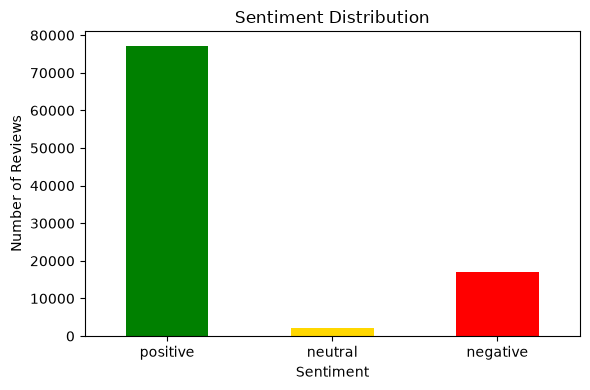

In [180]:
#sentiment distribution in the dataset
sentiment_order = ["positive", "neutral", "negative"]
sentiment_counts = (final_model_data['target_sentiment'].value_counts().reindex(sentiment_order))
plt.figure(figsize=(6,4))
sentiment_counts.plot(kind='bar', color=['green', 'gold', 'red'])
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



In [181]:
final_model_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 96402 entries, 0 to 205046
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customer_review   96402 non-null  object
 1   target_sentiment  96402 non-null  object
 2   target_label      96402 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 2.9+ MB


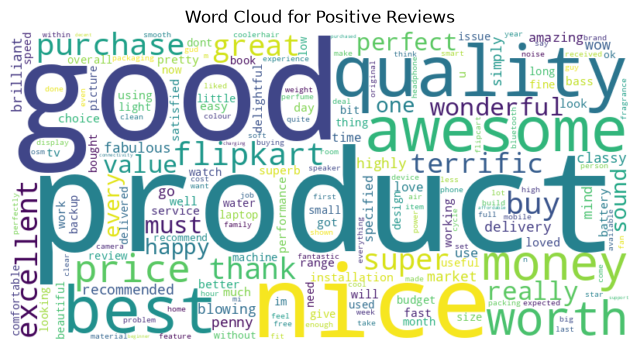

In [182]:
#word cloud for positive sentiments
positive_reviews = final_model_data[final_model_data['target_sentiment']=='positive']['customer_review']
positive_text = ' '.join(positive_reviews)
wordcloud = WordCloud(width=800, height=400, background_color="white", collocations=False).generate(positive_text)

plt.figure(figsize=(8,6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for Positive Reviews')
plt.show()

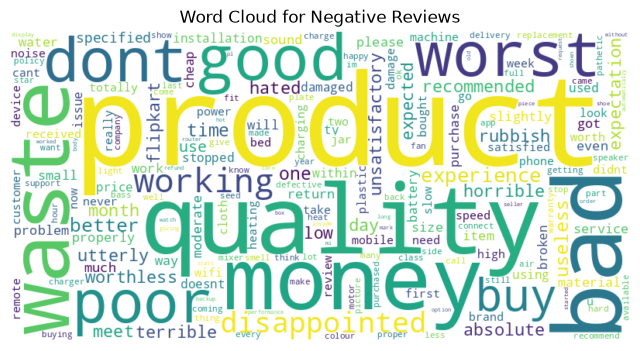

In [183]:
#word cloud for negative sentiments
negative_reviews = final_model_data[final_model_data['target_sentiment']=='negative']['customer_review']
negative_text = ' '.join(negative_reviews)
wordcloud = WordCloud(width=800, height=400, background_color="white", collocations=False).generate(negative_text)

plt.figure(figsize=(8,6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for Negative Reviews')
plt.show()

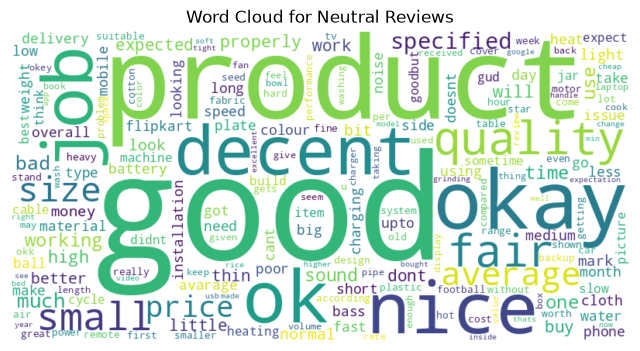

In [184]:
#word cloud for neutral sentiments
neutral_reviews = final_model_data[final_model_data['target_sentiment']=='neutral']['customer_review']
neutral_text = ' '.join(neutral_reviews)
wordcloud = WordCloud(width=800, height=400, background_color="white", collocations=False).generate(neutral_text)

plt.figure(figsize=(8,6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for Neutral Reviews')
plt.show()

In [185]:
print("Original rows:", len(feedback))
print("Final rows:", len(final_model_data))

print(
    f"Rows retained: "
    f"{len(final_model_data)/len(feedback):.2%}"
)

Original rows: 205047
Final rows: 96402
Rows retained: 47.01%
